# =========================================================
# RAIL DEFECT SEGMENTATION & SEVERITY PIPELINE (SINGLE FILE)
# Model: U-Net++ with EfficientNet-B0
# Task : Binary segmentation (class-wise folders)
# Class - Corrugation of Rails
# =========================================================

STEP 0️⃣ – GLOBAL SETTINGS (RUN FIRST)

In [1]:
!pip install segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.7 MB/s eta 0:00:00


In [2]:
import os
import cv2
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import albumentations as A
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp


In [3]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TARGET_DEFECT = "corrugation"
EPOCHS = 20
BATCH_SIZE = 4
LR = 1e-4


✅ Verify

In [4]:
print("Device:", DEVICE)
print("Target defect:", TARGET_DEFECT)


Device: cuda
Target defect: corrugation


STEP 1️⃣ – DATASET CLASS (NO AUGMENTATION YET)

STEP 2️⃣ – DISPLAY FEW SAMPLES AFTER LOADING DATASET ✅ (POINT 1)

In [5]:
class RailDataset(Dataset):
    def __init__(self, defect_root_dir, transform=None):
        """
        defect_root_dir example:
        /content/drive/MyDrive/.../Training Set/Corrugation of Rails
        """
        self.samples = []
        self.transform = transform

        img_dir = os.path.join(defect_root_dir, "Images")
        mask_dir = os.path.join(defect_root_dir, "masks")

        if not os.path.exists(img_dir):
            raise FileNotFoundError(f"Images folder not found: {img_dir}")
        if not os.path.exists(mask_dir):
            raise FileNotFoundError(f"Masks folder not found: {mask_dir}")

        for name in sorted(os.listdir(img_dir)):
            img_path = os.path.join(img_dir, name)
            base = os.path.splitext(name)[0]
            mask_path = os.path.join(mask_dir, base + ".png")

            if os.path.exists(mask_path):
                self.samples.append((img_path, mask_path))

        if len(self.samples) == 0:
            raise RuntimeError("No image–mask pairs found")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, mask_path = self.samples[idx]

        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        mask = (mask > 0).astype("uint8")

        # --- SMALL, CONTROLLED DILATION ---
        kernel = np.ones((5, 5), np.uint8)   # 5x5 is SAFE
        mask = cv2.dilate(mask, kernel, iterations=1)

        mask = mask.astype("float32")


        if self.transform:
            aug = self.transform(image=image, mask=mask)
            image, mask = aug["image"], aug["mask"]

        image = torch.tensor(image).permute(2,0,1).float() / 255.0
        mask  = torch.tensor(mask).unsqueeze(0)

        return image, mask, img_path


In [6]:
show_samples(train_ds_plain)


NameError: name 'show_samples' is not defined

In [7]:
def show_samples(dataset, n=3):
    plt.figure(figsize=(8, 3*n))

    for i in range(n):
        img, mask, _ = dataset[i]   # ✅ unpack 3 values, ignore filename

        plt.subplot(n, 2, 2*i+1)
        plt.imshow(img.permute(1,2,0))
        plt.title("Image")
        plt.axis("off")

        plt.subplot(n, 2, 2*i+2)
        plt.imshow(mask.squeeze(), cmap="gray")
        plt.title("Mask")
        plt.axis("off")

    plt.show()



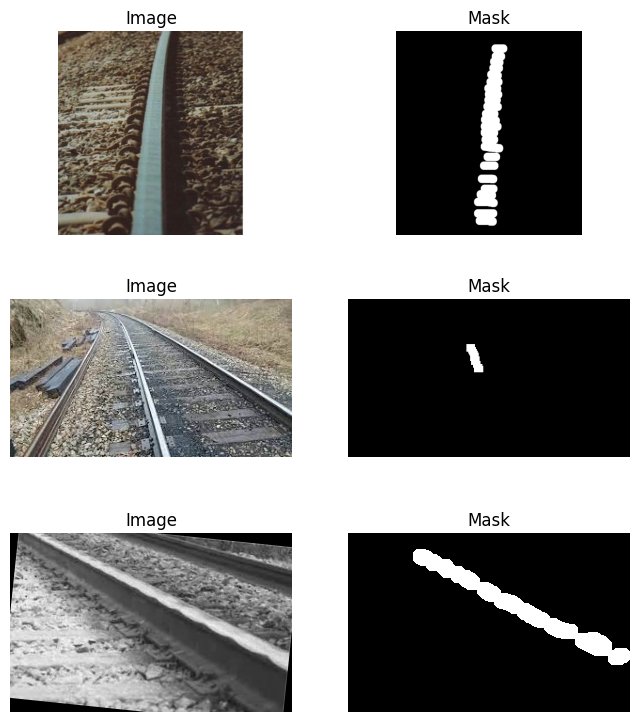

In [10]:
train_defect_path = "/content/drive/MyDrive/Severity Calculation Data Set/With Split/Training Set/Corrugation of Rails"

train_ds_plain = RailDataset(train_defect_path)
show_samples(train_ds_plain)


In [9]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


STEP 3️⃣ – ENVIRONMENT-WISE DATA AUGMENTATION + DISPLAY ✅ (POINT 2)

Morning

In [11]:
# -------------------------
# Sample environmental augmentations
# -------------------------
aug_rain = A.Compose([
    A.RandomRain(p=1.0)
])

aug_fog = A.Compose([
    A.RandomFog(
        fog_coef_lower=0.3,
        fog_coef_upper=0.6,
        alpha_coef=0.1,
        p=1.0
    )
])

aug_snow = A.Compose([
    A.RandomSnow(
        snow_point_lower=0.1,
        snow_point_upper=0.3,
        brightness_coeff=1.5,
        p=1.0
    )
])

# -------------------------
# Sample lighting augmentations
# -------------------------
aug_morning = A.Compose([
    A.RandomBrightnessContrast(
        brightness_limit=(0.1, 0.3),
        contrast_limit=(0, 0.1),
        p=1.0
    )
])

aug_evening = A.Compose([
    A.RandomBrightnessContrast(
        brightness_limit=(-0.3, -0.1),
        contrast_limit=(0, 0.1),
        p=1.0
    )
])

aug_night = A.Compose([
    A.RandomBrightnessContrast(
        brightness_limit=(-0.5, -0.3),
        contrast_limit=(0.1, 0.3),
        p=1.0
    )
])


/tmp/ipython-input-830839087.py:9: UserWarning: Argument(s) 'fog_coef_lower, fog_coef_upper' are not valid for transform RandomFog
  A.RandomFog(
/tmp/ipython-input-830839087.py:18: UserWarning: Argument(s) 'snow_point_lower, snow_point_upper' are not valid for transform RandomSnow
  A.RandomSnow(


In [12]:
def show_augmentations(dataset, aug_list, titles):
    img, mask, _ = dataset[0]   # ✅ unpack 3 values, ignore filename

    img = img.permute(1, 2, 0).cpu().numpy()
    mask = mask.squeeze().cpu().numpy()

    plt.figure(figsize=(15, 3))

    for i, aug in enumerate(aug_list):
        out = aug(image=img, mask=mask)

        plt.subplot(1, len(aug_list), i + 1)
        plt.imshow(out["image"])
        plt.title(titles[i])
        plt.axis("off")

    plt.show()



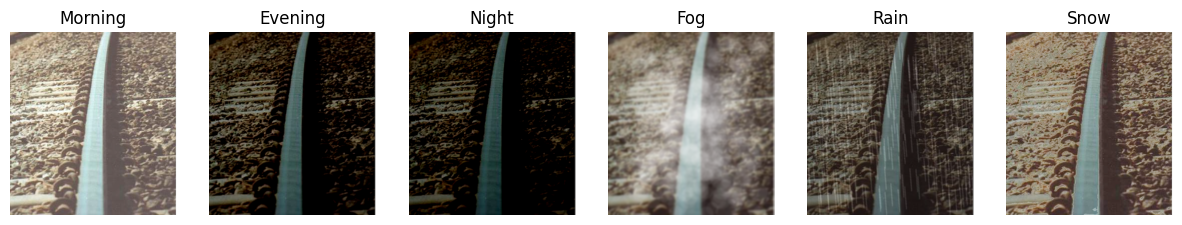

In [13]:
show_augmentations(
    train_ds_plain,
    [aug_morning, aug_evening, aug_night, aug_fog, aug_rain, aug_snow],
    ["Morning", "Evening", "Night", "Fog", "Rain", "Snow"]
)


STEP 4️⃣ – FINAL TRANSFORMS & LOADERS

In [14]:
train_tfms = A.Compose([
    A.Resize(512,512),
    A.HorizontalFlip(p=0.5),
    A.OneOf([aug_morning, aug_evening, aug_night, aug_fog, aug_rain], p=0.7)
])

val_tfms = A.Compose([A.Resize(512,512)])


In [15]:
train_ds = RailDataset("/content/drive/MyDrive/Severity Calculation Data Set/With Split/Training Set/Corrugation of Rails", train_tfms)
val_ds   = RailDataset("/content/drive/MyDrive/Severity Calculation Data Set/With Split/Validation Set/Corrugation of Rails", val_tfms)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

print("Train samples:", len(train_ds))
print("Val samples:", len(val_ds))


Train samples: 175
Val samples: 38


HOW TO VERIFY AUGMENTATION IS REALLY APPLIED (VISUAL PROOF)

In [16]:
def show_augmented_samples(dataset, n=5):
    plt.figure(figsize=(15, 3))

    for i in range(n):
        img, _, _ = dataset[i]   # ✅ unpack 3 values, ignore mask & filename

        plt.subplot(1, n, i + 1)
        plt.imshow(img.permute(1, 2, 0))
        plt.axis("off")

    plt.show()



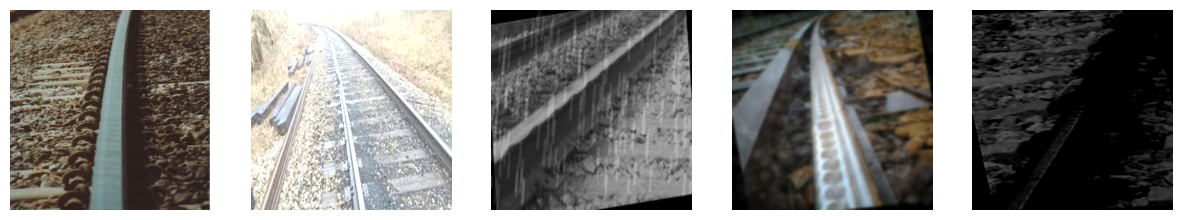

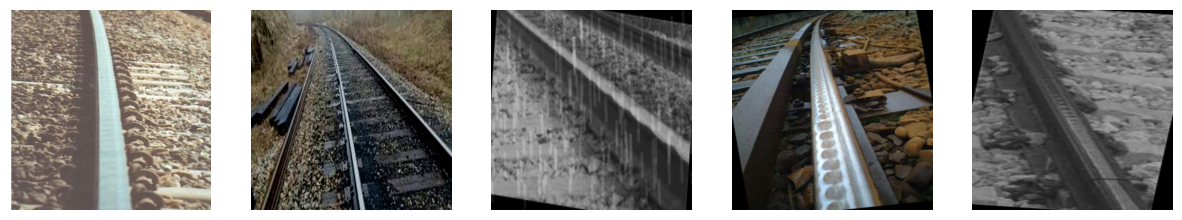

In [17]:
show_augmented_samples(train_ds)
show_augmented_samples(train_ds)


STEP 5️⃣ – MODEL, LOSS, METRICS ✅ (POINT 3)

In [18]:
model = smp.UnetPlusPlus(
    encoder_name="efficientnet-b0",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1
).to(DEVICE)



/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

In [19]:
from scipy.ndimage import distance_transform_edt

def boundary_loss(pred, gt):
    """
    Normalized boundary loss (stable).
    """
    gt_np = gt.detach().cpu().numpy()

    # Distance transform
    dist = distance_transform_edt(1 - gt_np)

    # Normalize distance map to [0,1]
    dist = dist / (dist.max() + 1e-8)

    dist = torch.tensor(dist, device=pred.device).float()

    pred = torch.sigmoid(pred)

    return (pred * dist).mean()




In [20]:
# =========================
# OPTION 2: FOCAL TVERSKY LOSS
# =========================

bce = nn.BCEWithLogitsLoss()

tversky = smp.losses.TverskyLoss(
    mode="binary",
    alpha=0.7,
    beta=0.3
)

def loss_fn(pred, gt):
    return (
        0.50 * bce(pred, gt) +
        0.40 * tversky(pred, gt) +
        0.10 * boundary_loss(pred, gt)
    )




In [21]:
def dice_score(pred, gt, eps=1e-7):
    pred = (torch.sigmoid(pred) > 0.5).float()
    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum()
    return (2*inter + eps) / (union + eps)


Hausdorff distance

In [22]:
from scipy.spatial.distance import directed_hausdorff
import numpy as np


In [23]:
def hausdorff_distance(pred_mask, gt_mask):
    """
    Computes symmetric Hausdorff Distance (in pixels)
    pred_mask, gt_mask: binary numpy arrays (H,W)
    """
    pred_pts = np.argwhere(pred_mask > 0)
    gt_pts   = np.argwhere(gt_mask > 0)

    # If either mask is empty, HD is undefined → return large value
    if len(pred_pts) == 0 or len(gt_pts) == 0:
        return np.nan

    hd1 = directed_hausdorff(pred_pts, gt_pts)[0]
    hd2 = directed_hausdorff(gt_pts, pred_pts)[0]

    return max(hd1, hd2)


STEP 6️⃣ – TRAINING + ALL METRICS + RUNTIME ✅ (POINT 4)

6.1 METRIC FUNCTIONS (ADD ONCE)

In [24]:
def iou_score(pred, gt, eps=1e-7):
    pred = (torch.sigmoid(pred) > 0.5).float()
    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum() - inter
    return (inter + eps) / (union + eps)

def pixel_accuracy(pred, gt):
    pred = (torch.sigmoid(pred) > 0.5).float()
    correct = (pred == gt).float().sum()
    total = torch.numel(pred)
    return correct / total

def precision_score(pred, gt, eps=1e-7):
    pred = (torch.sigmoid(pred) > 0.5).float()
    tp = (pred * gt).sum()
    fp = (pred * (1 - gt)).sum()
    return (tp + eps) / (tp + fp + eps)

def recall_score(pred, gt, eps=1e-7):
    pred = (torch.sigmoid(pred) > 0.5).float()
    tp = (pred * gt).sum()
    fn = ((1 - pred) * gt).sum()
    return (tp + eps) / (tp + fn + eps)


6.2 HISTORY DICTIONARY (FOR CURVES LATER)

In [38]:
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    #verbose=True
)


start_time = time.time()



In [39]:
history = {
    # Loss
    "train_loss": [],
    "val_loss": [],

    # Dice & IoU
    "train_dice": [],
    "val_dice": [],
    "train_iou": [],
    "val_iou": [],

    # Accuracy / Precision / Recall
    "train_acc": [],
    "val_acc": [],
    "train_prec": [],
    "val_prec": [],
    "train_rec": [],
    "val_rec": [],

    # Hausdorff
    "train_hd": [],
    "val_hd": []
}


In [40]:
best_val_dice = 0.0
epoch_times = []
total_training_start = time.time()

for epoch in range(EPOCHS):
    epoch_start = time.time()

    # ================= TRAIN =================
    model.train()
    tl = td = ti = tacc = tprec = trec = 0.0

    train_hd = []

    for imgs, masks, _ in train_loader:   # ✅ FIXED
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

        preds = model(imgs)
        loss = loss_fn(preds, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        tl += loss.item()
        td += dice_score(preds, masks).item()
        ti += iou_score(preds, masks).item()
        tacc  += pixel_accuracy(preds, masks).item()
        tprec += precision_score(preds, masks).item()
        trec  += recall_score(preds, masks).item()


        # Hausdorff (TRAIN)
        preds_bin = (torch.sigmoid(preds) > 0.5).float()
        for i in range(preds_bin.size(0)):
            pred_np = preds_bin[i, 0].cpu().numpy()
            gt_np   = masks[i, 0].cpu().numpy()
            hd = hausdorff_distance(pred_np, gt_np)
            if not np.isnan(hd):
                train_hd.append(hd)

    tl /= len(train_loader)
    td /= len(train_loader)
    ti /= len(train_loader)
    tacc  /= len(train_loader)
    tprec /= len(train_loader)
    trec  /= len(train_loader)

    mean_train_hd = np.mean(train_hd) if len(train_hd) > 0 else np.nan
    history["train_hd"].append(mean_train_hd)

    # ================= VALIDATION =================
    model.eval()
    vl = vd = vi = vacc = vprec = vrec = 0.0
    val_hd = []

    with torch.no_grad():
        for imgs, masks, _ in val_loader:   # ✅ FIXED
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            preds = model(imgs)

            vl += loss_fn(preds, masks).item()
            vd += dice_score(preds, masks).item()
            vi += iou_score(preds, masks).item()
            vacc += pixel_accuracy(preds, masks).item()
            vprec += precision_score(preds, masks).item()
            vrec += recall_score(preds, masks).item()

            # Hausdorff (VAL)
            preds_bin = (torch.sigmoid(preds) > 0.5).float()
            for i in range(preds_bin.size(0)):
                pred_np = preds_bin[i, 0].cpu().numpy()
                gt_np   = masks[i, 0].cpu().numpy()
                hd = hausdorff_distance(pred_np, gt_np)
                if not np.isnan(hd):
                    val_hd.append(hd)

    vl /= len(val_loader)
    vd /= len(val_loader)
    vi /= len(val_loader)
    vacc /= len(val_loader)
    vprec /= len(val_loader)
    vrec /= len(val_loader)
    mean_val_hd = np.mean(val_hd) if len(val_hd) > 0 else np.nan
    history["val_hd"].append(mean_val_hd)

    scheduler.step(vd)

    # ================= SAVE HISTORY =================
    history["train_loss"].append(tl)
    history["val_loss"].append(vl)
    history["train_dice"].append(td)
    history["val_dice"].append(vd)
    history["train_iou"].append(ti)
    history["val_iou"].append(vi)
    history["train_acc"].append(tacc)
    history["val_acc"].append(vacc)
    history["train_prec"].append(tprec)
    history["val_prec"].append(vprec)
    history["train_rec"].append(trec)
    history["val_rec"].append(vrec)





    # ================= SAVE BEST MODEL =================
    if vd > best_val_dice:
        best_val_dice = vd
        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_dice": best_val_dice,
            "architecture": "Unet++",
            "encoder": "efficientnet-b0",
            "defect": "Corrugation of Rails",
            "image_size": 512
        }
        torch.save(checkpoint, "best_unetpp_effb0_corrugation.pth")

    # ================= RUNTIME =================
    epoch_time = time.time() - epoch_start
    epoch_times.append(epoch_time)

    # ================= PRINT METRICS (COMPLETE) =================
    print(
    f"Epoch [{epoch+1}/{EPOCHS}] | Time {epoch_time:.1f}s\n"
    f"  Train → Loss={tl:.4f}, Dice={td:.4f}, IoU={ti:.4f}, "
    f"Acc={tacc:.4f}, Prec={tprec:.4f}, Rec={trec:.4f}, HD={mean_train_hd:.2f}px\n"
    f"  Val   → Loss={vl:.4f}, Dice={vd:.4f}, IoU={vi:.4f}, "
    f"Acc={vacc:.4f}, Prec={vprec:.4f}, Rec={vrec:.4f}, HD={mean_val_hd:.2f}px\n"
    )


# ================= TOTAL TIME =================
total_training_time = time.time() - total_training_start
print("Total training time:", total_training_time)
print("Avg epoch time:", sum(epoch_times) / len(epoch_times))




Epoch [1/20] | Time 40.6s
  Train → Loss=0.1430, Dice=0.8328, IoU=0.7159, Acc=0.9725, Prec=0.8312, Rec=0.8423, HD=54.83px
  Val   → Loss=0.2121, Dice=0.7414, IoU=0.5969, Acc=0.9608, Prec=0.6447, Rec=0.8895, HD=77.46px

Epoch [2/20] | Time 39.3s
  Train → Loss=0.1366, Dice=0.8367, IoU=0.7217, Acc=0.9727, Prec=0.8396, Rec=0.8412, HD=51.95px
  Val   → Loss=0.1922, Dice=0.7484, IoU=0.6059, Acc=0.9644, Prec=0.6827, Rec=0.8448, HD=72.16px

Epoch [3/20] | Time 40.9s
  Train → Loss=0.1356, Dice=0.8295, IoU=0.7116, Acc=0.9720, Prec=0.8369, Rec=0.8271, HD=51.63px
  Val   → Loss=0.1935, Dice=0.7460, IoU=0.6014, Acc=0.9639, Prec=0.6799, Rec=0.8387, HD=78.35px

Epoch [4/20] | Time 40.6s
  Train → Loss=0.1334, Dice=0.8268, IoU=0.7077, Acc=0.9716, Prec=0.8299, Rec=0.8310, HD=57.70px
  Val   → Loss=0.1839, Dice=0.7505, IoU=0.6086, Acc=0.9656, Prec=0.6949, Rec=0.8266, HD=78.45px

Epoch [5/20] | Time 42.1s
  Train → Loss=0.1242, Dice=0.8370, IoU=0.7217, Acc=0.9733, Prec=0.8431, Rec=0.8347, HD=45.22px
  

ADD THIS FUNCTION (RUN AFTER TRAINING)

In [41]:
import numpy as np
import torch

def find_best_iou_threshold(model, val_loader):
    model.eval()
    thresholds = np.arange(0.4, 0.8, 0.05)

    best_iou = 0.0
    best_t = 0.5

    with torch.no_grad():
        for t in thresholds:
            iou_sum = 0.0

            for imgs, masks, _ in val_loader:   # ✅ FIX HERE
                imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
                probs = torch.sigmoid(model(imgs))
                preds = (probs > t).float()
                iou_sum += iou_score(preds, masks).item()

            mean_iou = iou_sum / len(val_loader)

            print(f"Threshold {t:.2f} → IoU {mean_iou:.4f}")

            if mean_iou > best_iou:
                best_iou = mean_iou
                best_t = t

    print(f"\n✔ Best threshold = {best_t:.2f}, IoU = {best_iou:.4f}")
    return best_t, best_iou


In [42]:
best_t, best_iou = find_best_iou_threshold(model, val_loader)



Threshold 0.40 → IoU 0.6102
Threshold 0.45 → IoU 0.6113
Threshold 0.50 → IoU 0.6121
Threshold 0.55 → IoU 0.6127
Threshold 0.60 → IoU 0.6130
Threshold 0.65 → IoU 0.6130
Threshold 0.70 → IoU 0.6128
Threshold 0.75 → IoU 0.6119

✔ Best threshold = 0.65, IoU = 0.6130


STEP 7️⃣ – ACCURACY & LOSS CURVES ✅ (POINT 5)

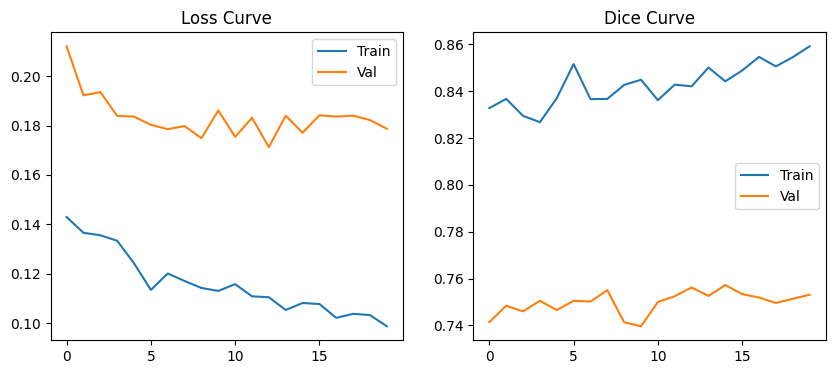

In [43]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history["train_loss"], label="Train")
plt.plot(history["val_loss"], label="Val")
plt.title("Loss Curve")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history["train_dice"], label="Train")
plt.plot(history["val_dice"], label="Val")
plt.title("Dice Curve")
plt.legend()
plt.show()




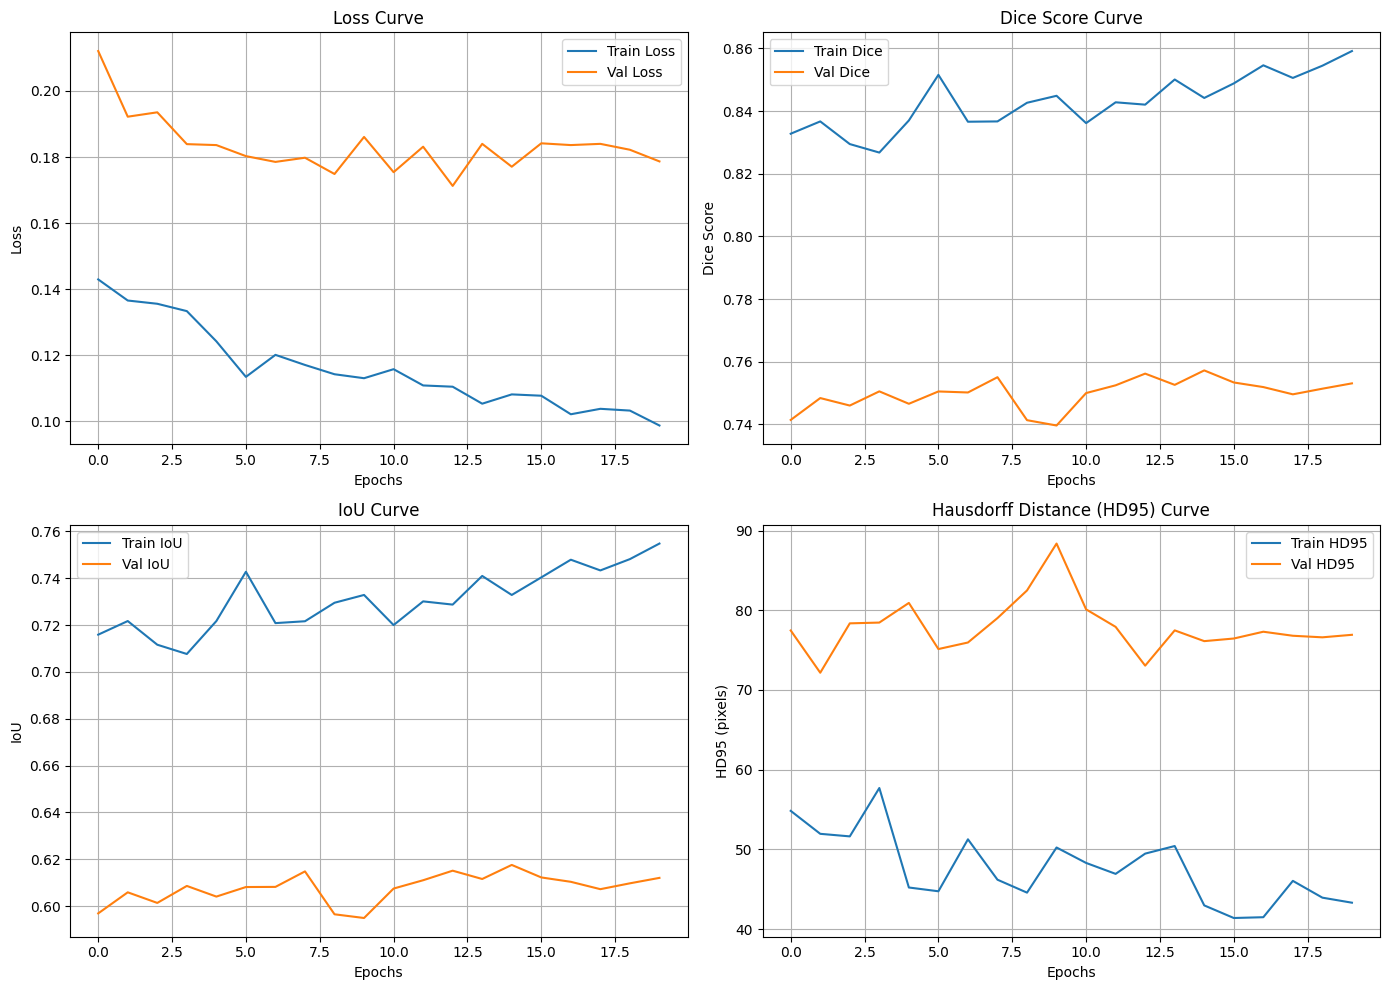

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))

# ---------------- Loss Curve ----------------
plt.subplot(2, 2, 1)
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Val Loss")
plt.title("Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# ---------------- Dice Curve ----------------
plt.subplot(2, 2, 2)
plt.plot(history["train_dice"], label="Train Dice")
plt.plot(history["val_dice"], label="Val Dice")
plt.title("Dice Score Curve")
plt.xlabel("Epochs")
plt.ylabel("Dice Score")
plt.legend()
plt.grid(True)

# ---------------- IoU Curve ----------------
plt.subplot(2, 2, 3)
plt.plot(history["train_iou"], label="Train IoU")
plt.plot(history["val_iou"], label="Val IoU")
plt.title("IoU Curve")
plt.xlabel("Epochs")
plt.ylabel("IoU")
plt.legend()
plt.grid(True)

# ---------------- Hausdorff Distance Curve ----------------
plt.subplot(2, 2, 4)
plt.plot(history["train_hd"], label="Train HD95")
plt.plot(history["val_hd"], label="Val HD95")
plt.title("Hausdorff Distance (HD95) Curve")
plt.xlabel("Epochs")
plt.ylabel("HD95 (pixels)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


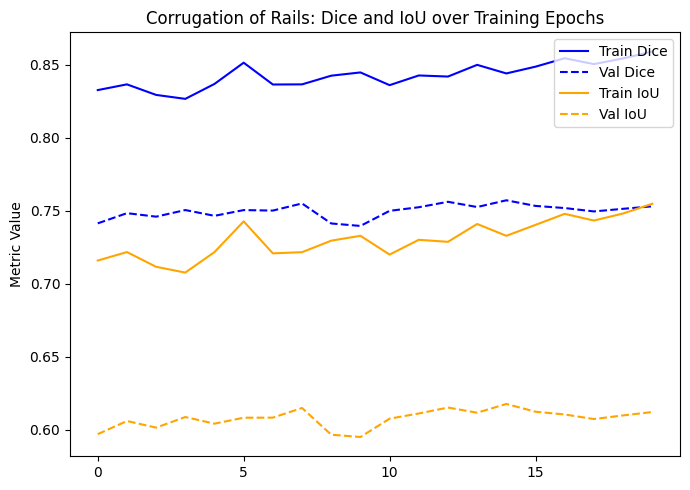

In [45]:
import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(len(history["train_dice"]))

plt.figure(figsize=(7,5))

# Dice
plt.plot(epochs, history["train_dice"], label="Train Dice", color="blue", linestyle="-")
plt.plot(epochs, history["val_dice"], label="Val Dice", color="blue", linestyle="--")

# IoU
plt.plot(epochs, history["train_iou"], label="Train IoU", color="orange", linestyle="-")
plt.plot(epochs, history["val_iou"], label="Val IoU", color="orange", linestyle="--")

plt.title("Corrugation of Rails: Dice and IoU over Training Epochs")
plt.xticks(np.arange(0, len(epochs), 5))
plt.ylabel("Metric Value")
plt.legend()
plt.tight_layout()
plt.show()



Apply CRF post-processing once

In [46]:
import time
import numpy as np
import torch
import torch.nn as nn
from scipy.spatial.distance import directed_hausdorff



In [47]:
def hausdorff_distance_95(pred_mask, gt_mask):
    pred_pts = np.argwhere(pred_mask > 0)
    gt_pts   = np.argwhere(gt_mask > 0)

    if len(pred_pts) == 0 or len(gt_pts) == 0:
        return np.nan

    d1 = directed_hausdorff(pred_pts, gt_pts)[0]
    d2 = directed_hausdorff(gt_pts, pred_pts)[0]

    return np.percentile([d1, d2], 95)


In [49]:
best_val_dice = 0.0
epoch_times = []
total_start = time.time()

for epoch in range(EPOCHS):
    start = time.time()

    # ================= TRAIN =================
    model.train()
    tl = td = ti = tacc = tprec = trec = 0.0


    for imgs, masks , _ in train_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

        preds = model(imgs)
        loss = loss_fn(preds, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        tl += loss.item()
        td += dice_score(preds, masks).item()
        ti += iou_score(preds, masks).item()
        tacc  += pixel_accuracy(preds, masks).item()
        tprec += precision_score(preds, masks).item()
        trec  += recall_score(preds, masks).item()


    tl /= len(train_loader)
    td /= len(train_loader)
    ti /= len(train_loader)
    tacc  /= len(train_loader)
    tprec /= len(train_loader)
    trec  /= len(train_loader)


    # ================= VALIDATION =================
    model.eval()
    vl = vd = vi = vacc = vprec = vrec = 0.0
    val_hd95 = []

    with torch.no_grad():
        for imgs, masks, _ in val_loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            preds = model(imgs)

            vl += loss_fn(preds, masks).item()
            vd += dice_score(preds, masks).item()
            vi += iou_score(preds, masks).item()
            vacc += pixel_accuracy(preds, masks).item()
            vprec += precision_score(preds, masks).item()
            vrec += recall_score(preds, masks).item()

            probs = torch.sigmoid(preds)

            for i in range(imgs.size(0)):
                 pred_bin = (probs[i,0] > 0.5).cpu().numpy()
                 gt_np    = masks[i,0].cpu().numpy()

                 hd95 = hausdorff_distance_95(pred_bin, gt_np)
                 if not np.isnan(hd95):
                     val_hd95.append(hd95)

    vl /= len(val_loader)
    vd /= len(val_loader)
    vi /= len(val_loader)
    vacc /= len(val_loader)
    vprec /= len(val_loader)
    vrec /= len(val_loader)
    mean_hd95 = np.mean(val_hd95)

    # ================= SAVE BEST MODEL =================
    if vd > best_val_dice:
        best_val_dice = vd
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "best_val_dice": best_val_dice
        }, "best_unetpp_effb0_corrugation.pth")

    epoch_time = time.time() - start
    epoch_times.append(epoch_time)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | Time {epoch_time:.1f}s\n"
        f"  Train → Loss={tl:.4f}, Dice={td:.4f}, IoU={ti:.4f}\n"
        f"  Val   → Loss={vl:.4f}, Dice={vd:.4f}, IoU={vi:.4f}, "
        f"Acc={vacc:.4f}, Prec={vprec:.4f}, Rec={vrec:.4f}, HD95={mean_hd95:.2f}px\n"
    )

print("\nTotal training time:", time.time() - total_start)
print("Avg epoch time:", sum(epoch_times)/len(epoch_times))


Epoch [1/20] | Time 37.6s
  Train → Loss=0.1004, Dice=0.8560, IoU=0.7509
  Val   → Loss=0.1827, Dice=0.7520, IoU=0.6103, Acc=0.9645, Prec=0.6764, Rec=0.8582, HD95=73.48px

Epoch [2/20] | Time 37.9s
  Train → Loss=0.0988, Dice=0.8603, IoU=0.7562
  Val   → Loss=0.1835, Dice=0.7524, IoU=0.6110, Acc=0.9643, Prec=0.6719, Rec=0.8664, HD95=73.43px

Epoch [3/20] | Time 37.7s
  Train → Loss=0.0976, Dice=0.8614, IoU=0.7582
  Val   → Loss=0.1867, Dice=0.7499, IoU=0.6078, Acc=0.9636, Prec=0.6652, Rec=0.8718, HD95=73.38px

Epoch [4/20] | Time 36.1s
  Train → Loss=0.1000, Dice=0.8577, IoU=0.7527
  Val   → Loss=0.1815, Dice=0.7534, IoU=0.6124, Acc=0.9649, Prec=0.6771, Rec=0.8601, HD95=74.24px

Epoch [5/20] | Time 37.4s
  Train → Loss=0.0967, Dice=0.8630, IoU=0.7603
  Val   → Loss=0.1815, Dice=0.7536, IoU=0.6122, Acc=0.9649, Prec=0.6782, Rec=0.8584, HD95=73.91px

Epoch [6/20] | Time 37.1s
  Train → Loss=0.0990, Dice=0.8568, IoU=0.7506
  Val   → Loss=0.1817, Dice=0.7530, IoU=0.6114, Acc=0.9648, Prec=0.

Draw Graph

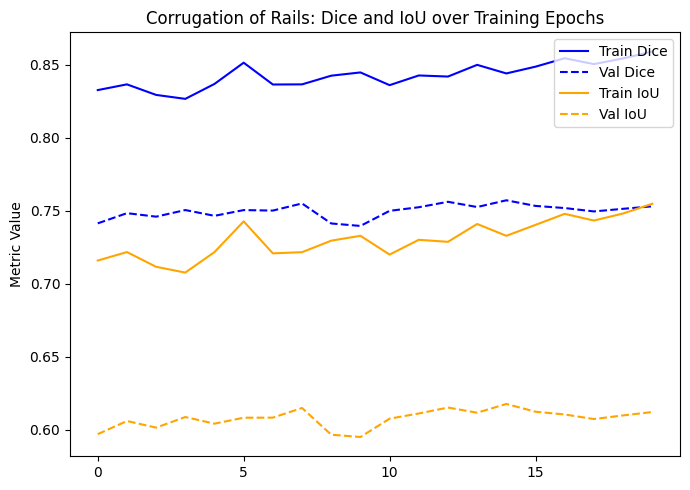

In [50]:
import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(len(history["train_dice"]))

plt.figure(figsize=(7,5))

# Dice
plt.plot(epochs, history["train_dice"], label="Train Dice", color="blue", linestyle="-")
plt.plot(epochs, history["val_dice"], label="Val Dice", color="blue", linestyle="--")

# IoU
plt.plot(epochs, history["train_iou"], label="Train IoU", color="orange", linestyle="-")
plt.plot(epochs, history["val_iou"], label="Val IoU", color="orange", linestyle="--")

plt.title("Corrugation of Rails: Dice and IoU over Training Epochs")
plt.xticks(np.arange(0, len(epochs), 5))
plt.ylabel("Metric Value")
plt.legend()
plt.tight_layout()
plt.show()


Run on Test Data

STEP 1 — LOAD BEST TRAINED MODEL

In [51]:
checkpoint = torch.load(
    "best_unetpp_effb0_corrugation.pth",
    map_location=DEVICE
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("✔ Best model loaded")
print("Best Val Dice:", checkpoint["best_val_dice"])


✔ Best model loaded
Best Val Dice: 0.754951012134552


STEP 2 — TEST DATASET & LOADER

In [52]:
TEST_PATH = (
    "/content/drive/MyDrive/Severity Calculation Data Set/"
    "With Split/Test Set/Corrugation of Rails"
)

test_ds = RailDataset(TEST_PATH, transform=val_tfms)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

print("Test samples:", len(test_ds))


Test samples: 37


STEP 3 — HD95 FUNCTION (ROBUST & FINAL)

In [53]:
from scipy.spatial.distance import directed_hausdorff

def hausdorff_distance_95(pred_mask, gt_mask):
    pred_pts = np.argwhere(pred_mask > 0)
    gt_pts   = np.argwhere(gt_mask > 0)

    if len(pred_pts) == 0 or len(gt_pts) == 0:
        return np.nan

    d1 = directed_hausdorff(pred_pts, gt_pts)[0]
    d2 = directed_hausdorff(gt_pts, pred_pts)[0]

    return np.percentile([d1, d2], 95)


STEP 4 — RUN MODEL ON TEST DATA (CORE)

In [54]:
test_dice = test_iou = test_acc = test_prec = test_rec = 0.0
test_hd95 = []

with torch.no_grad():
    for imgs, masks, _ in test_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

        preds = model(imgs)
        probs = torch.sigmoid(preds)
        preds_bin = (probs > 0.5).float()

        test_dice += dice_score(preds, masks).item()
        test_iou  += iou_score(preds, masks).item()
        test_acc  += pixel_accuracy(preds, masks).item()
        test_prec += precision_score(preds, masks).item()
        test_rec  += recall_score(preds, masks).item()

        # HD95 (per image)
        for i in range(preds_bin.size(0)):
            pred_np = preds_bin[i,0].cpu().numpy()
            gt_np   = masks[i,0].cpu().numpy()

            hd95 = hausdorff_distance_95(pred_np, gt_np)
            if not np.isnan(hd95):
                test_hd95.append(hd95)

# Averages
test_dice /= len(test_loader)
test_iou  /= len(test_loader)
test_acc  /= len(test_loader)
test_prec /= len(test_loader)
test_rec  /= len(test_loader)
mean_test_hd95 = np.mean(test_hd95)


STEP 5 — PRINT FINAL TEST RESULTS (PAPER-READY)

In [ ]:
print("\n========== FINAL TEST RESULTS ==========")
print(f"Dice Score       : {test_dice:.4f}")
print(f"IoU              : {test_iou:.4f}")
print(f"Accuracy         : {test_acc:.4f}")
print(f"Precision        : {test_prec:.4f}")
print(f"Recall           : {test_rec:.4f}")
print(f"HD95 (pixels)    : {mean_test_hd95:.2f}")



========== FINAL TEST RESULTS ==========
Dice Score       : 0.7480
IoU              : 0.6023
Accuracy         : 0.9646
Precision        : 0.7505
Recall           : 0.7603
HD95 (pixels)    : 42.57


STEP 1 — SEVERITY CALCULATION FUNCTION (FINAL)

In [55]:
def severity_and_action(mask, defect_name):
    """
    mask: binary numpy array (H,W)
    returns: severity, action, defect area
    """
    area = int(mask.sum())

    if defect_name == "Corrugation of Rails":
        if area < 500:
            severity = "Low"
            action = "Routine monitoring"
        elif area < 1500:
            severity = "Moderate"
            action = "Scheduled rail grinding"
        else:
            severity = "Severe"
            action = "Immediate grinding or rail replacement"

    elif defect_name == "Rail Wear":
        if area < 400:
            severity = "Low"
            action = "Condition monitoring"
        elif area < 1200:
            severity = "Moderate"
            action = "Preventive maintenance"
        else:
            severity = "Severe"
            action = "Rail replacement required"

    else:
        severity = "Moderate"
        action = "Maintenance inspection required"

    return severity, action, area




In [56]:
def severity_and_action(mask, defect_name):
    """
    mask: binary numpy array (H,W)
    returns: severity, action, defect area
    """
    area = int(mask.sum())

    if defect_name == "Corrugation of Rails":
        if area < 500:
            severity = "Low"
            action = "Routine monitoring"
        elif area < 1500:
            severity = "Moderate"
            action = "Scheduled rail grinding"
        else:
            severity = "Severe"
            action = "Immediate grinding or rail replacement"

    else:
        severity = "Moderate"
        action = "Detailed maintenance inspection"

    return severity, action, area


STEP 6 (OPTIONAL) — STEP 2 — VISUALIZATION WITH SEVERITY (COPY–PASTE)

In [57]:
import matplotlib.pyplot as plt
import numpy as np
import torch

def visualize_prediction_gt_severity_action(
    model,
    loader,
    defect_name,
    num_samples=5,
    threshold=0.5
):
    model.eval()
    imgs, masks , _ = next(iter(loader))
    imgs, masks , _ = imgs.to(DEVICE), masks.to(DEVICE)

    with torch.no_grad():
        probs = torch.sigmoid(model(imgs))

    plt.figure(figsize=(18, 4 * num_samples))

    for i in range(min(num_samples, imgs.size(0))):
        img_np = imgs[i].permute(1, 2, 0).cpu().numpy()
        gt_np = masks[i, 0].cpu().numpy()
        pred_np = (probs[i, 0].cpu().numpy() > threshold).astype(np.uint8)

        severity, action, area = severity_and_action(pred_np, defect_name)

        # -------- ORIGINAL IMAGE --------
        plt.subplot(num_samples, 3, i * 3 + 1)
        plt.imshow(img_np)
        plt.title("Original Image")
        plt.axis("off")

        # -------- GROUND TRUTH --------
        plt.subplot(num_samples, 3, i * 3 + 2)
        plt.imshow(gt_np, cmap="gray")
        plt.title("Ground Truth Mask")
        plt.axis("off")

        # -------- PREDICTED MASK (B/W ONLY) --------
        ax = plt.subplot(num_samples, 3, i * 3 + 3)
        ax.imshow(pred_np, cmap="gray")
        ax.axis("off")

        # --- TEXT ABOVE MASK (ORDERED) ---
        ax.text(
            0.5, 1.18,
            "Predicted Mask",
            fontsize=12,
            fontweight="bold",
            ha="center",
            va="bottom",
            transform=ax.transAxes
        )

        ax.text(
            0.5, 1.10,
            f"Severity: {severity} | Area: {area} px",
            color="red",
            fontsize=11,
            fontweight="bold",
            ha="center",
            va="bottom",
            transform=ax.transAxes
        )

        ax.text(
            0.5, 1.03,
            f"Action: {action}",
            color="red",
            fontsize=11,
            fontweight="bold",
            ha="center",
            va="bottom",
            transform=ax.transAxes
        )

    plt.tight_layout()
    plt.show()


RUN VISUALIZATION ON TEST DATA

One more visualization with image name

In [58]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import os

def visualize_prediction_gt_severity_action(
    model,
    loader,
    defect_name,
    num_samples=5,
    threshold=0.5
):
    model.eval()

    images, masks, img_names = next(iter(loader))
    images = images.to(DEVICE)
    masks  = masks.to(DEVICE)

    with torch.no_grad():
        probs = torch.sigmoid(model(images))

    plt.figure(figsize=(18, 4 * num_samples))

    for i in range(min(num_samples, images.size(0))):

        # ---------------- FILE NAME ----------------
        img_name = os.path.basename(img_names[i])
        print(f"Test image: {img_name}")

        # ---------------- DATA ----------------
        img_np  = images[i].permute(1, 2, 0).cpu().numpy()
        gt_np   = masks[i, 0].cpu().numpy()
        pred_np = (probs[i, 0].cpu().numpy() > threshold).astype(np.uint8)

        severity, action, area = severity_and_action(pred_np, defect_name)

        # ---------------- ORIGINAL IMAGE ----------------
        plt.subplot(num_samples, 3, i * 3 + 1)
        plt.imshow(img_np)
        plt.title("Original Image")
        plt.axis("off")

        # ---------------- GROUND TRUTH ----------------
        plt.subplot(num_samples, 3, i * 3 + 2)
        plt.imshow(gt_np, cmap="gray")
        plt.title("Ground Truth Mask")
        plt.axis("off")

        # ---------------- PREDICTED MASK (B/W) ----------------
        ax = plt.subplot(num_samples, 3, i * 3 + 3)
        ax.imshow(pred_np, cmap="gray")
        ax.axis("off")

        # ---------------- TEXT ABOVE MASK ----------------
        ax.text(
            0.5, 1.18,
            "Predicted Mask",
            fontsize=12,
            fontweight="bold",
            ha="center",
            transform=ax.transAxes
        )

        ax.text(
            0.5, 1.10,
            f"Severity: {severity} | Area: {area} px",
            color="red",
            fontsize=11,
            fontweight="bold",
            ha="center",
            transform=ax.transAxes
        )

        ax.text(
            0.5, 1.03,
            f"Action: {action}",
            color="red",
            fontsize=11,
            fontweight="bold",
            ha="center",
            transform=ax.transAxes
        )

    plt.tight_layout()
    plt.show()



Special Loader for Visualization

In [59]:
vis_loader = DataLoader(
    test_ds,
    batch_size=5,     # same as num_samples
    shuffle=False
)


Use this loader for visualization

Test image: CR_214.jpeg
Test image: CR_215.jpeg
Test image: CR_216.jpeg
Test image: CR_217.jpeg
Test image: CR_218.jpeg


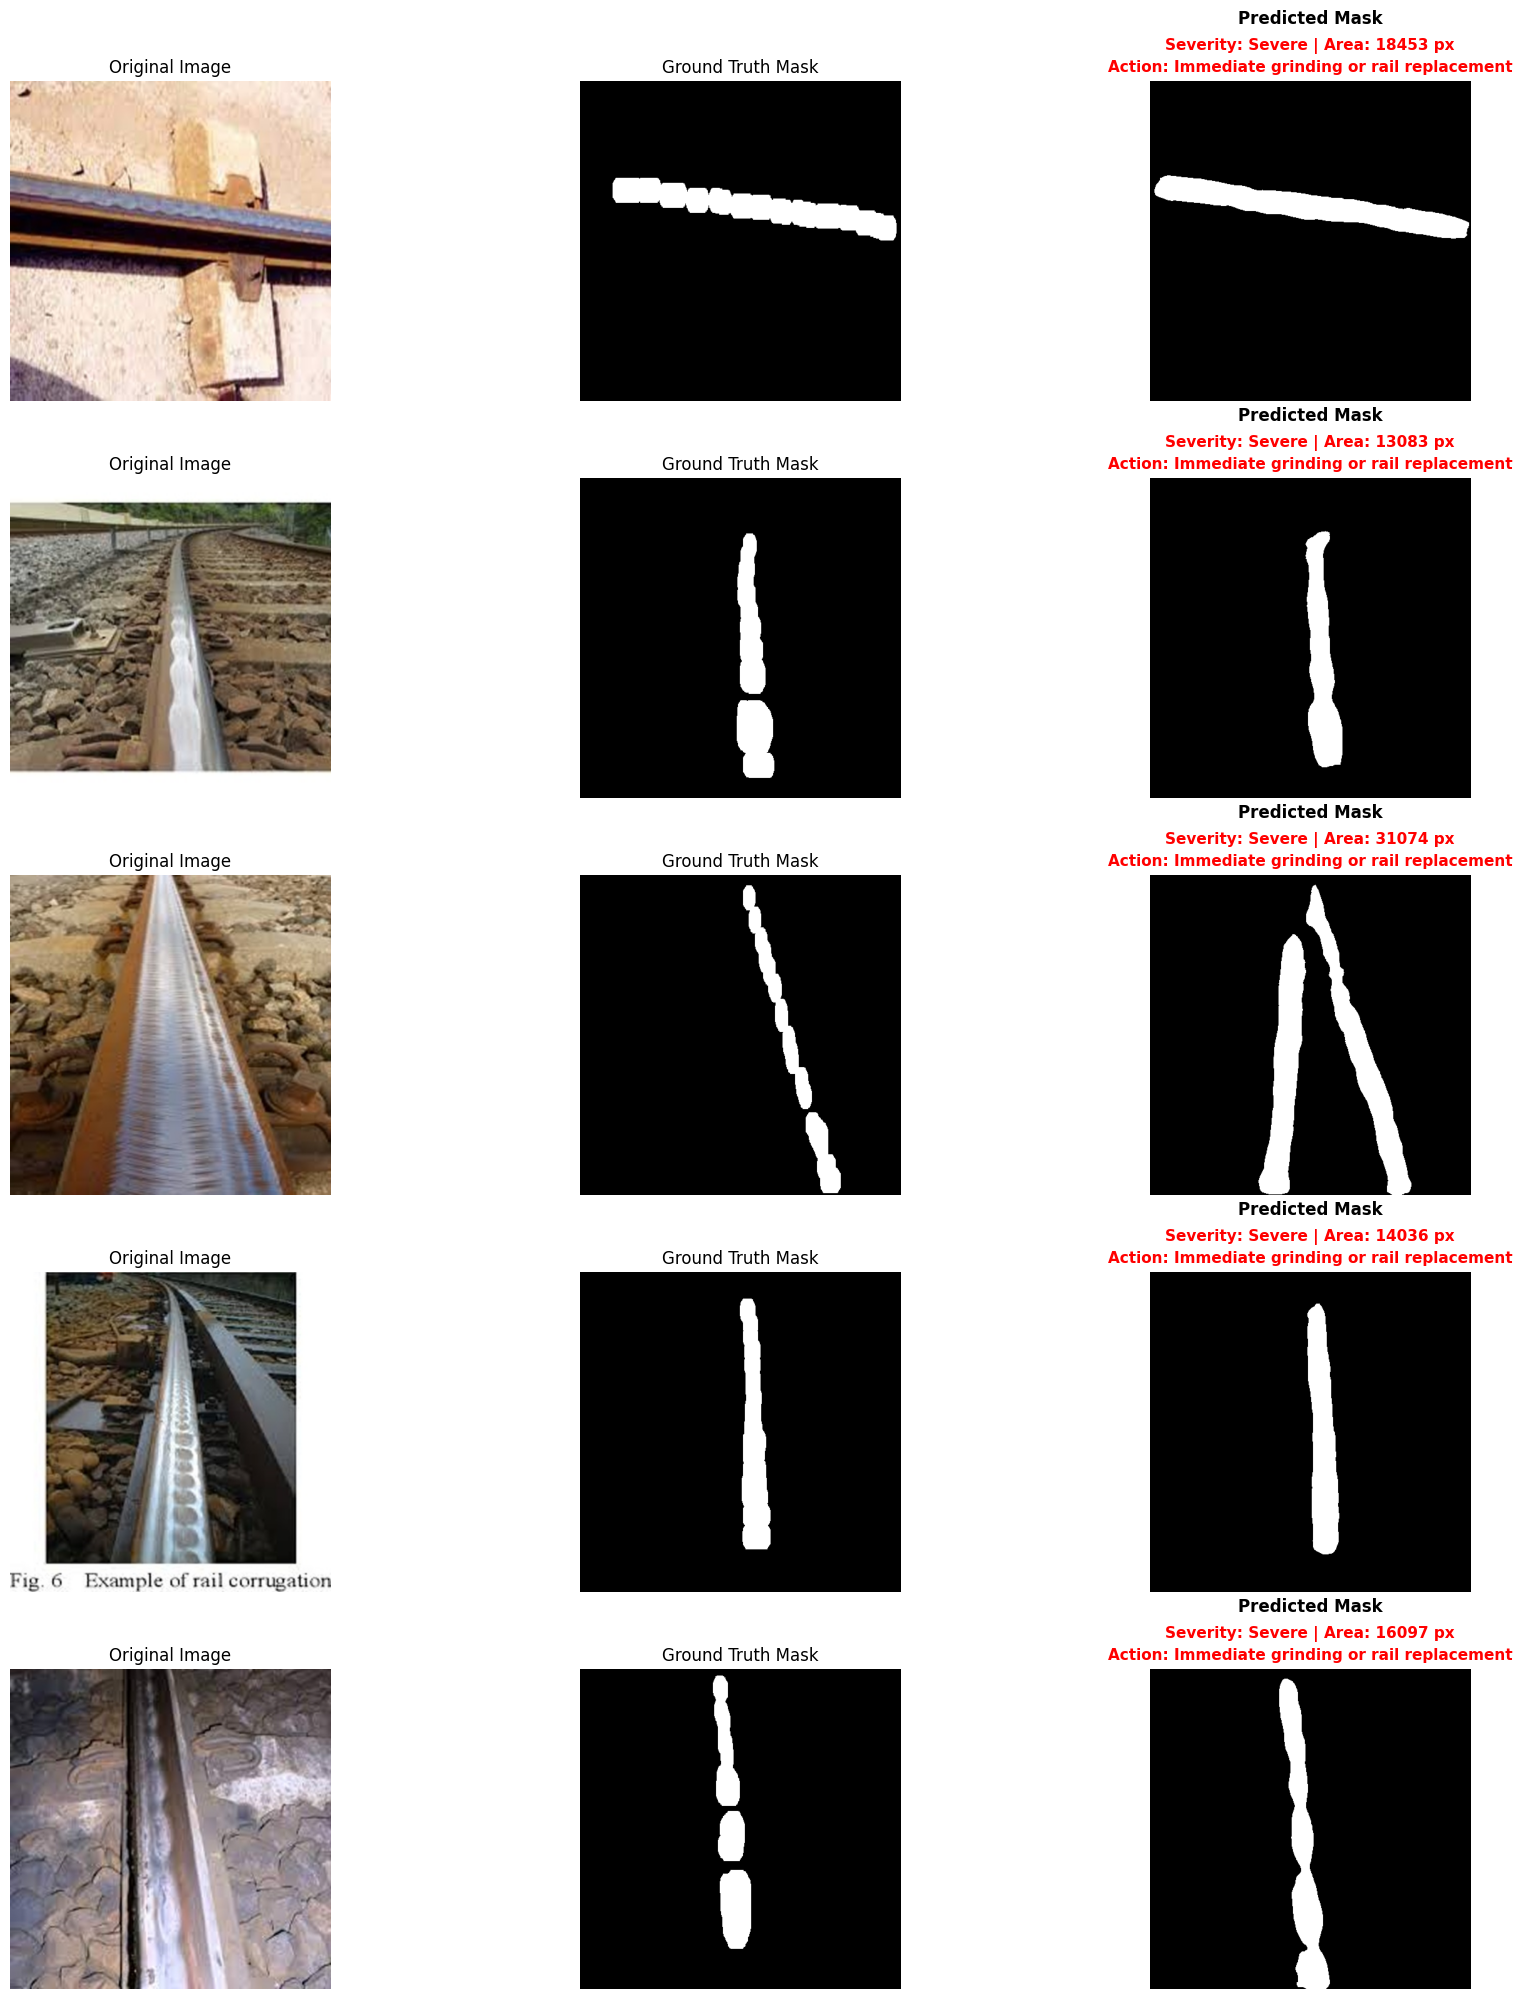

In [60]:
visualize_prediction_gt_severity_action(
    model=model,
    loader=vis_loader,
    defect_name="Corrugation of Rails",
    num_samples=5
)


Run visualization on test data

Test image: CR_214.jpeg
Test image: CR_215.jpeg
Test image: CR_216.jpeg
Test image: CR_217.jpeg


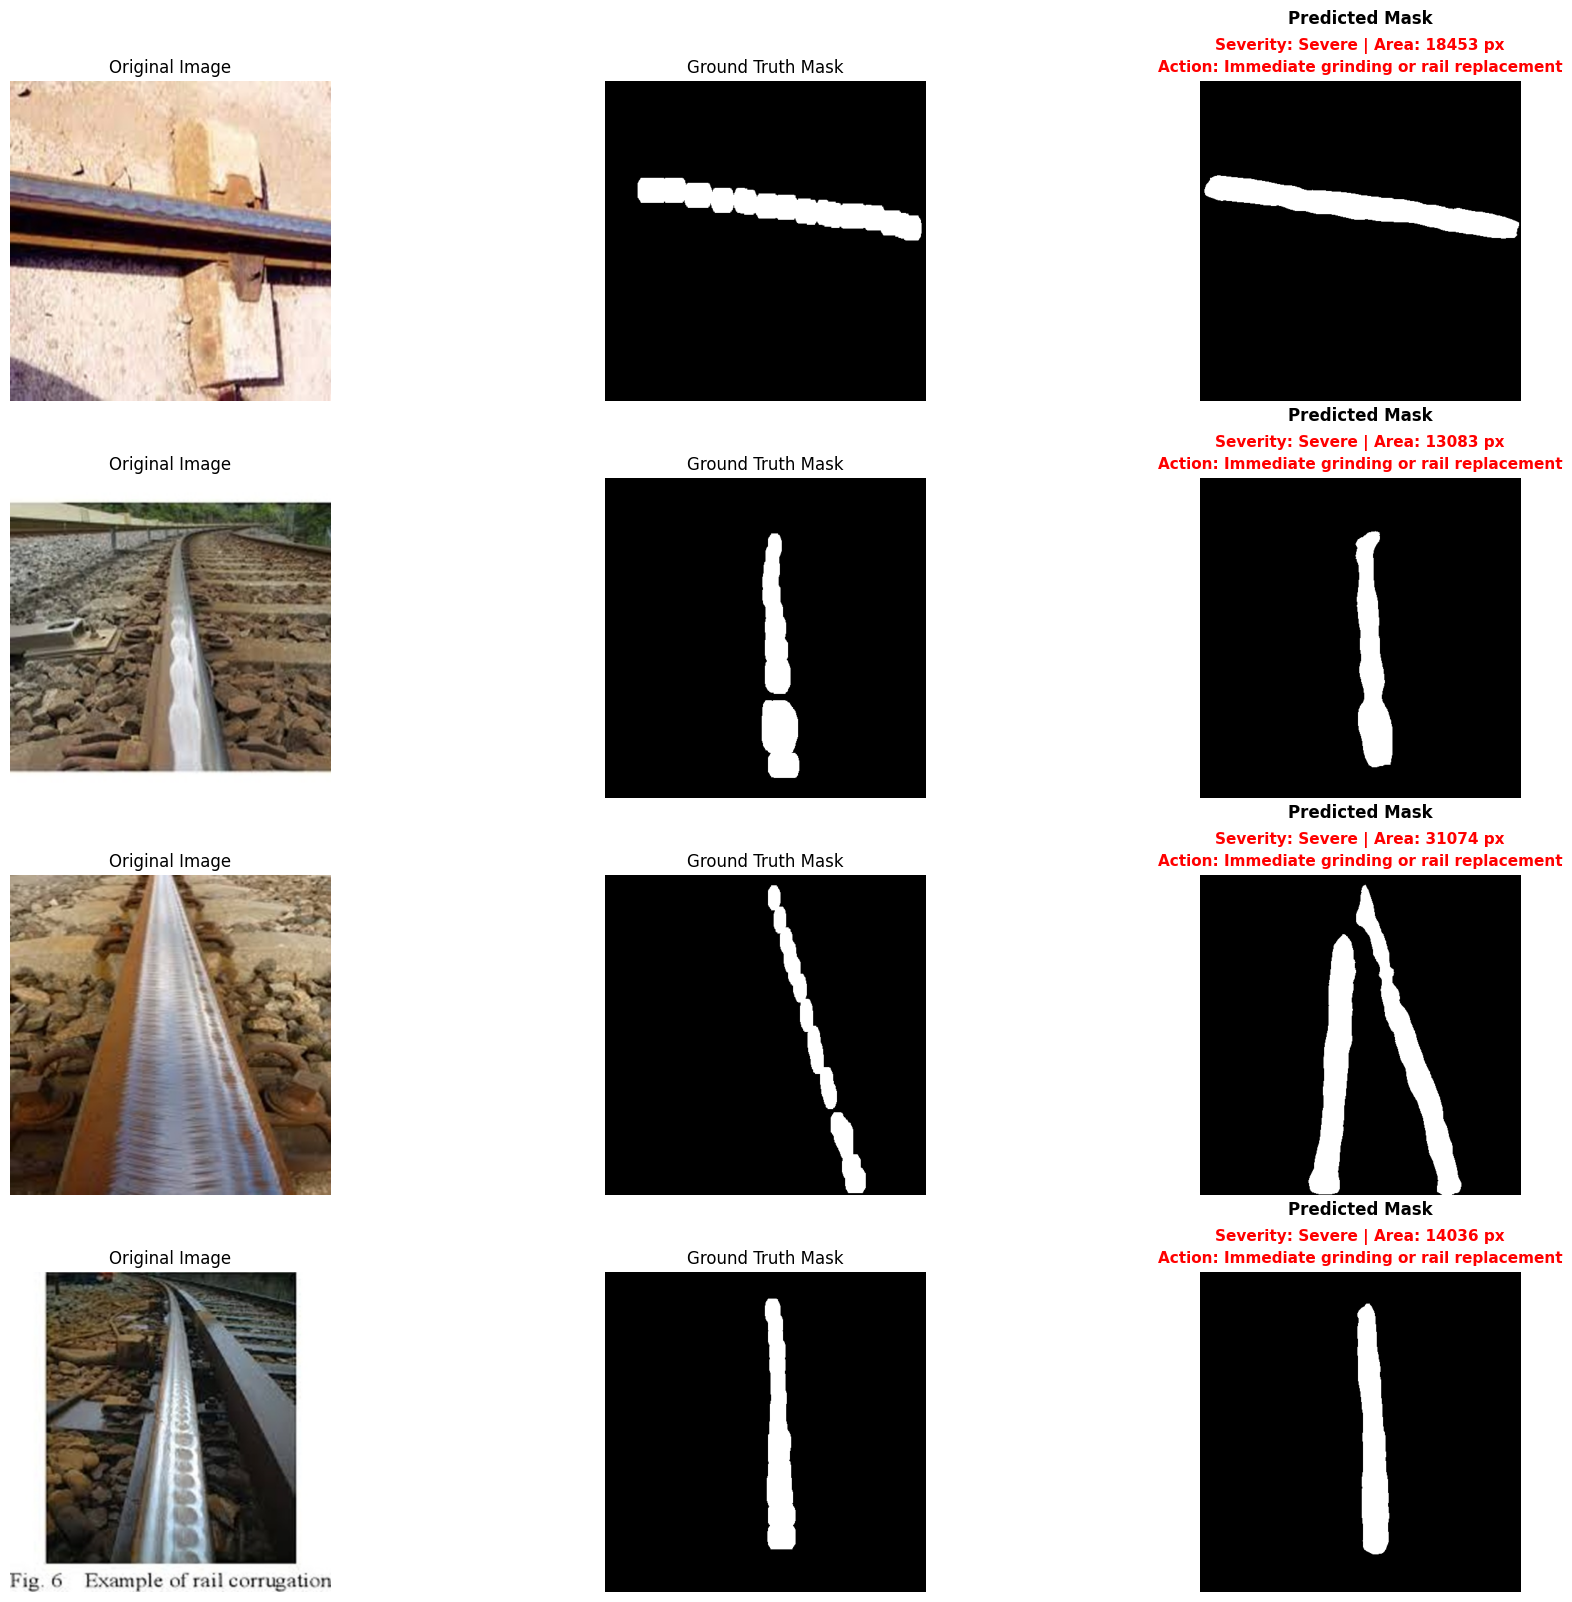

In [61]:
visualize_prediction_gt_severity_action(
    model=model,
    loader=test_loader,
    defect_name="Corrugation of Rails",
    num_samples=5
)



STEP 1: EXTRACT FINAL / BEST VALUES AUTOMATICALLY

In [62]:
# ---------------- Fetch metrics automatically ----------------

train_metrics = {
    "Dice": history["train_dice"][-1],
    "IoU": history["train_iou"][-1],
    "Accuracy": history["val_acc"][-1] if "val_acc" in history else None,
    "Precision": history["val_prec"][-1] if "val_prec" in history else None,
    "Recall": history["val_rec"][-1] if "val_rec" in history else None,
    "HD95": history["train_hd"][-1]
}

val_metrics = {
    "Dice": history["val_dice"][-1],
    "IoU": history["val_iou"][-1],
    "Accuracy": history["val_acc"][-1],
    "Precision": history["val_prec"][-1],
    "Recall": history["val_rec"][-1],
    "HD95": history["val_hd"][-1]
}

test_metrics = {
    "Dice": test_dice,
    "IoU": test_iou,
    "Accuracy": test_acc,
    "Precision": test_prec,
    "Recall": test_rec,
    "HD95": test_hd95
}


STEP 2: BUILD RESULTS TABLE AUTOMATICALLY (NO MANUAL VALUES)

In [63]:
import numpy as np
import pandas as pd

test_hd95_mean = float(np.mean(test_metrics["HD95"]))

results_table = pd.DataFrame({
    "Dataset Split": ["Training", "Validation", "Test"],
    "Dice Score": [
        round(train_metrics["Dice"], 4),
        round(val_metrics["Dice"], 4),
        round(test_metrics["Dice"], 4)
    ],
    "IoU": [
        round(train_metrics["IoU"], 4),
        round(val_metrics["IoU"], 4),
        round(test_metrics["IoU"], 4)
    ],
    "Accuracy": [
        round(train_metrics["Accuracy"], 4),
        round(val_metrics["Accuracy"], 4),
        round(test_metrics["Accuracy"], 4)
    ],
    "Precision": [
        round(train_metrics["Precision"], 4),
        round(val_metrics["Precision"], 4),
        round(test_metrics["Precision"], 4)
    ],
    "Recall": [
        round(train_metrics["Recall"], 4),
        round(val_metrics["Recall"], 4),
        round(test_metrics["Recall"], 4)
    ],
    "HD95 (pixels)": [
        round(train_metrics["HD95"], 2),
        round(val_metrics["HD95"], 2),
        round(test_hd95_mean, 2)
    ]
})

results_table



,Dataset Split,Dice Score,IoU,Accuracy,Precision,Recall,HD95 (pixels)
0,Training,0.8592,0.7548,0.9649,0.6811,0.8530,43.31
1,Validation,0.7531,0.6121,0.9649,0.6811,0.8530,76.92
2,Test,0.8045,0.6774,0.9653,0.7902,0.8295,43.67


STEP 3 (OPTIONAL): SAVE TABLE FOR PAPER / RECORDS

In [ ]:
results_table.to_csv("corrugation_results_table.csv", index=False)
